# Generative Artificial Intelligence — Lab 2: GANs and Conditional GANs
**University of Boumerdes (UMBB) — Master 2, Field I2A — Faculty of Sciences, Department of Computer Science — Academic year 2026/2027**

with PyTorch, on MNIST, then on Pokémon and flower images

## Objectives
At the end of this lab, you will be able to:
- build a generator and a discriminator in PyTorch and train them one against the other;
- write the training loop of a GAN in two phases, and explain the role of `.detach()` and of the labels 0 and 1;
- replace the linear layers with convolutions (DCGAN) and check the size of every layer;
- build a conditional GAN (cGAN): give the class to both networks and choose the class of the generated image;
- download a dataset from Kaggle (`kagglehub` or *Add Input*), prepare colour images (transparency, size, range) and do the same work on 64 × 64 colour images: a DCGAN on Pokémon images, a conditional GAN on flower photos;
- read the loss curves of a GAN, and check if a generator copies its training images.

This document explains every block of code of the lab. Read the explanation, run the code, look at the output, then answer the questions. Some lines of code are missing: they are marked `# TODO` with a hint. Complete them before you run the block. The Python packages needed for the lab are listed in the file `requirements.txt`.

**Plan.** The lab is done on MNIST, step by step. After each part, an exercise asks you to do the same work on a new colour dataset from Kaggle.

| Part | Model | Dataset | Images |
|---|---|---|---|
| Section 1 | GAN (linear), then DCGAN | MNIST | 1 × 28 × 28, gray |
| Exercise A | DCGAN | Pokémon (819 images, no labels) | 3 × 64 × 64, colour |
| Section 2 | conditional GAN | MNIST (10 digits) | 1 × 28 × 28, gray |
| Exercise B | conditional GAN | Flowers (5 classes) | 3 × 64 × 64, colour |

# Section 0 — Prepare the environment

## 0.1 On your PC (CPU or GPU)
We use the environment `genai` of Lab 1. If you do not have it, follow Section 0 of Lab 1 (clone base, install PyTorch for the CPU or for your GPU). Then open Anaconda Prompt (or a terminal) in the folder of the lab:

```
conda activate genai
pip install -r requirements.txt
jupyter notebook
```

The only new package is `kagglehub`: it downloads datasets from Kaggle (Exercises A and B). In Jupyter, choose the kernel "Python (genai)".

## 0.2 On Google Colab or Kaggle
PyTorch is already installed. Choose a GPU: on Colab, *Runtime → Change runtime type → T4 GPU*; on Kaggle, in the right panel, *Accelerator → GPU* and *Internet → On*. `kagglehub` is installed on both. On Colab, if the import fails, run `!pip install kagglehub` in a cell.

## 0.3 Check

In [1]:
import sys, platform
import torch, torchvision, numpy, matplotlib

print("Python :", sys.version.split()[0], "on", platform.system())
print("PyTorch :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

try:
    import kagglehub
    print("kagglehub is installed, version", kagglehub.__version__)
except ImportError:
    print("kagglehub is missing: run pip install kagglehub")

Python : 3.14.7 on Linux
PyTorch : 2.15.0+cu132
torchvision : 0.29.2+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 3050
kagglehub is installed, version 1.0.3


The line `CUDA available` must be `True` on Colab and Kaggle. On a PC without an NVIDIA GPU it is `False`: the lab still works, but slower.

> **Training time.** A GAN must be trained much longer than the autoencoders of Lab 1. The number of epochs in the code is chosen so that every section runs in a reasonable time on a CPU, so the images are not perfect. Each `n_epochs` line has a comment with a better value for a GPU. With a GPU, use these values: the difference is very visible.

# Section 1 — A GAN on MNIST

**Goal.** Two networks play a game:
- the **generator** $G$ takes a random vector $z$ (the noise, 100 numbers from $\mathcal{N}(0, 1)$) and returns an image $G(z)$;
- the **discriminator** $D$ takes an image and returns a score: high if it thinks the image is real, low if it thinks the image is fake.

$D$ learns to separate real and fake images. $G$ learns to fool $D$. At the end, we throw away $D$ and we keep $G$: it turns any random $z$ into a new digit.

## 1.1 Imports and helper functions

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.utils import make_grid

%matplotlib inline

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)


def show_images(images, nrow=8, title=None, size=6):
    # images: tensor (N, C, H, W) with values in [-1, 1]
    grid = make_grid(images.detach().cpu(), nrow=nrow, padding=2,
                     normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(size, size))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_losses(history, title):
    plt.figure(figsize=(7, 3.5))
    plt.plot(history["d"], label="discriminator", alpha=0.8)
    plt.plot(history["g"], label="generator", alpha=0.8)
    plt.xlabel("iteration")
    plt.ylabel("loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

PyTorch version: 2.15.0+cu132
Device: cuda


- `show_images` draws a batch of images as a grid with `make_grid`. It works for gray and colour images. `normalize=True, value_range=(-1, 1)` maps the values from $[-1, 1]$ back to $[0, 1]$ for the display.
- `plot_losses` draws the two losses (one value per batch). We use both functions in the whole lab.

## 1.2 The data

One batch: (128, 1, 28, 28)
Values between -1.0 and 1.0


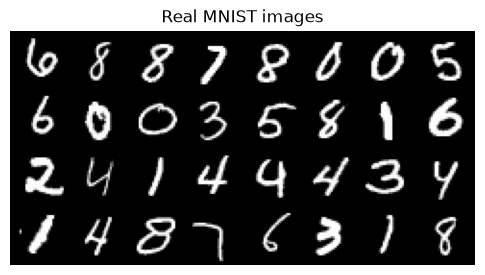

In [3]:
# ToTensor gives values in [0, 1]; Normalize(0.5, 0.5) maps them to [-1, 1],
# the same range as the Tanh at the output of the generator.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),   # [0, 1] -> [-1, 1]
])

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True,
                                           drop_last=True)

images, labels = next(iter(train_loader))
print("One batch:", tuple(images.shape))
print("Values between", images.min().item(), "and", images.max().item())
show_images(images[:32], title="Real MNIST images")

- `ToTensor()` gives pixels in $[0, 1]$. `Normalize(mean, std)` computes $(x - \text{mean})/\text{std}$ for each channel. Choose `mean` and `std` so that the pixels are in $[-1, 1]$ (MNIST has one channel: write them as tuples of one value).
- **Why?** The last layer of the generator is a `Tanh`, whose outputs are in $[-1, 1]$. Real and fake images must be in the same range, otherwise the discriminator wins at once just by looking at the range of the values.
- `drop_last=True`: all batches have exactly 128 images (the last, smaller batch is dropped). This keeps the BatchNorm layers of the next models stable.

Expected output:
```
One batch: (128, 1, 28, 28) | values between -1.0 and 1.0
```

## 1.3 A linear GAN

In [4]:
z_dim = 100   # size of the noise vector

class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 28 * 28), nn.Tanh())     # pixels in [-1, 1]

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)       # vector -> image


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                            # image -> vector
            nn.Linear(28 * 28, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1))                       # one score (a logit, no sigmoid)

    def forward(self, x):
        return self.net(x)


G = Generator(z_dim).to(device)
D = Discriminator().to(device)
print("Generator parameters    :", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

Generator parameters    : 559632
Discriminator parameters: 533505


| | Generator | Discriminator |
|---|---|---|
| input | noise $z$: 100 | image: 1 × 28 × 28, flattened to 784 |
| hidden layers | 256, 512 (LeakyReLU) | 512, 256 (LeakyReLU) |
| output | 784 values, Tanh, reshaped to 1 × 28 × 28 | 1 value (a logit) |

- The two networks are mirrors: $G$ goes from a small vector to an image, $D$ from an image to one number.
- `LeakyReLU(0.2)`: like ReLU, but negative inputs give a small negative output ($0.2x$) instead of 0. The gradient never becomes exactly zero: this helps the generator, which learns only through the gradients that come back from $D$.
- The discriminator has **no sigmoid**. Its output is a *logit* (any real number). The sigmoid is inside the loss (next block).

Expected output:
```
Generator parameters : 559632
Discriminator parameters: 533505
```

## 1.4 The loss and the training loop
The discriminator is a binary classifier: real → 1, fake → 0. With the binary cross-entropy, its loss is

$$L_D = -\big[\log D(x) + \log\big(1 - D(G(z))\big)\big]$$

and the generator wants $D$ to answer "real" on its images:

$$L_G = -\log D(G(z)).$$

(This is the "non-saturating" loss of the lecture. The original loss $\log(1 - D(G(z)))$ gives almost no gradient at the beginning, when $D$ easily rejects the fakes.)

In [5]:
criterion = nn.BCEWithLogitsLoss()   # sigmoid + binary cross-entropy, in one stable function


def train_gan(G, D, loader, n_epochs, z_dim, lr=2e-4):
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    fixed_z = torch.randn(64, z_dim, device=device)   # the same noise at every epoch
    history = {"d": [], "g": [], "samples": []}

    for epoch in range(1, n_epochs + 1):
        G.train(); D.train()
        for real, _ in loader:                         # the labels are not used
            real = real.to(device)
            B = real.size(0)
            ones = torch.ones(B, 1, device=device)
            zeros = torch.zeros(B, 1, device=device)

            # ---------- Phase 1: train the discriminator ----------
            z = torch.randn(B, z_dim, device=device)
            fake = G(z).detach()    # fake images WITHOUT gradient for G
            loss_d = criterion(D(real), ones) + criterion(D(fake), zeros)   # real -> 1, fake -> 0
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

            # ---------- Phase 2: train the generator ----------
            z = torch.randn(B, z_dim, device=device)
            fake = G(z)
            loss_g = criterion(D(fake), ones)   # the generator wants D to answer "real"
            opt_g.zero_grad()
            loss_g.backward()
            opt_g.step()

            history["d"].append(loss_d.item())
            history["g"].append(loss_g.item())

        G.eval()
        with torch.no_grad():
            history["samples"].append(G(fixed_z).cpu())
        print(f"Epoch {epoch:2d}/{n_epochs} | loss D: {loss_d.item():.3f} "
              f"| loss G: {loss_g.item():.3f}")
    return history

- `BCEWithLogitsLoss` = sigmoid + binary cross-entropy in one function. It is more stable than `Sigmoid` followed by `BCELoss`.
- **Two networks, so two optimizers.** `opt_d` changes only the weights of $D$, `opt_g` only the weights of $G$. The values `lr=2e-4` and `betas=(0.5, 0.999)` come from the DCGAN paper; they work well for most GANs.
- **Phase 1 (discriminator).** $D$ sees a batch of real images (target 1) and a batch of fake images (target 0). The fake images must be used as simple inputs: no gradient must go back into $G$. Find the tensor method that cuts a tensor from the computation graph.
- **Phase 2 (generator).** New fake images, this time *without* detach, and the target is **1**: the generator is rewarded when $D$ is fooled. The gradient goes through $D$ into $G$, but only `opt_g.step()` is called, so only $G$ changes.
- `fixed_z`: 64 noise vectors chosen once. After every epoch we draw $G(\texttt{fixed\_z})$: we see the *same* 64 images improve epoch after epoch.

## 1.5 Training

In [6]:
n_epochs = 30 if device.type == "cuda" else 5        # increase it if you have a GPU (30 or more)
history = train_gan(G, D, train_loader, n_epochs, z_dim)

Epoch  1/30 | loss D: 0.808 | loss G: 2.911
Epoch  2/30 | loss D: 0.467 | loss G: 2.950
Epoch  3/30 | loss D: 0.475 | loss G: 1.614
Epoch  4/30 | loss D: 0.509 | loss G: 2.948
Epoch  5/30 | loss D: 0.567 | loss G: 3.502
Epoch  6/30 | loss D: 0.486 | loss G: 3.037
Epoch  7/30 | loss D: 0.620 | loss G: 1.288
Epoch  8/30 | loss D: 0.387 | loss G: 3.119
Epoch  9/30 | loss D: 0.549 | loss G: 1.719
Epoch 10/30 | loss D: 1.209 | loss G: 5.019
Epoch 11/30 | loss D: 0.525 | loss G: 2.102
Epoch 12/30 | loss D: 0.618 | loss G: 2.577
Epoch 13/30 | loss D: 0.614 | loss G: 1.555
Epoch 14/30 | loss D: 0.683 | loss G: 1.391
Epoch 15/30 | loss D: 0.792 | loss G: 2.618
Epoch 16/30 | loss D: 0.824 | loss G: 1.170
Epoch 17/30 | loss D: 0.765 | loss G: 1.738
Epoch 18/30 | loss D: 0.973 | loss G: 1.573
Epoch 19/30 | loss D: 0.795 | loss G: 1.292
Epoch 20/30 | loss D: 0.842 | loss G: 1.025
Epoch 21/30 | loss D: 0.953 | loss G: 1.023
Epoch 22/30 | loss D: 0.957 | loss G: 0.907
Epoch 23/30 | loss D: 0.803 | lo

Expected output (the values change from one run to another):
```
Epoch  1/5 | loss D: 0.840 | loss G: 1.269
Epoch  2/5 | loss D: 0.788 | loss G: 3.581
Epoch  3/5 | loss D: 1.156 | loss G: 0.827
Epoch  4/5 | loss D: 1.908 | loss G: 1.335
Epoch  5/5 | loss D: 0.586 | loss G: 1.707
```

## 1.6 Results

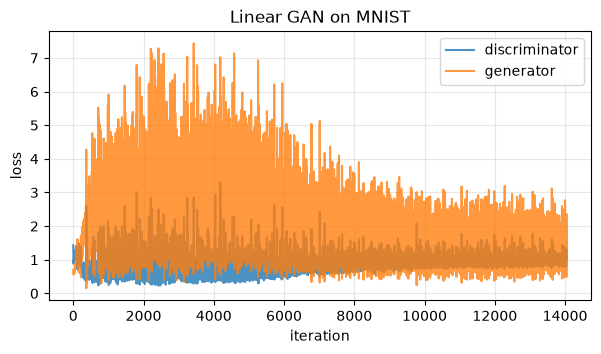

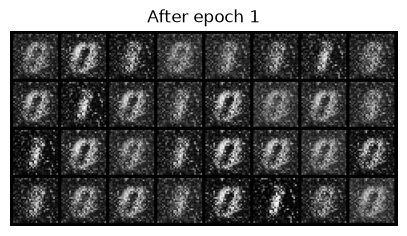

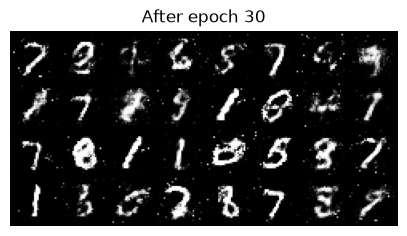

In [7]:
plot_losses(history, "Linear GAN on MNIST")

# the same 64 noise vectors, after the first and after the last epoch
show_images(history["samples"][0][:32], title="After epoch 1", size=5)
show_images(history["samples"][-1][:32], title=f"After epoch {n_epochs}", size=5)

The losses do **not** go down to zero like the loss of a classifier. Each network gets better, but so does its opponent: the two losses oscillate around a balance. A loss of $D$ that falls to 0 (and a loss of $G$ that keeps growing) means that $D$ has won and $G$ no longer learns.

The same noise vectors after the first epoch (left) and after the last epoch (right). After one epoch the generator only draws a grey blob in the middle of the image; after five epochs the blobs have the shape of digits, but they are still noisy. A linear generator needs many more epochs to give clean digits.

## 1.7 A convolutional GAN (DCGAN)
Images have a spatial structure. As in Lab 1 (convolutional autoencoder), we replace the linear layers by convolutions: `Conv2d` with `stride=2` in $D$ (the image becomes smaller), `ConvTranspose2d` with `stride=2` in $G$ (the image becomes larger).

In [8]:
class DCGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z_dim, 128 * 7 * 7),
                                nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),   # 7 -> 14
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1),     # 14 -> 28
            nn.Tanh())

    def forward(self, z):
        x = self.fc(z).view(-1, 128, 7, 7)       # vector -> 7 x 7 feature map
        return self.net(x)


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, stride=2, padding=1),              # 28 -> 14
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),            # 14 -> 7
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1))

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
G_dc = DCGenerator(z_dim).to(device)
D_dc = DCDiscriminator().to(device)

# check the shapes before training
z = torch.randn(4, z_dim, device=device)
print("generator output    :", tuple(G_dc(z).shape))
print("discriminator output:", tuple(D_dc(G_dc(z)).shape))

generator output    : (4, 1, 28, 28)
discriminator output: (4, 1)


| Generator | | Discriminator | |
|---|---|---|---|
| $z$ | 100 | image | 1 × 28 × 28 |
| Linear, reshape | 128 × 7 × 7 | Conv2d(k=4, s=2, p=1) | 64 × 14 × 14 |
| ConvTranspose2d(k=4, s=2, p=1) | 64 × 14 × 14 | Conv2d(k=4, s=2, p=1) | 128 × 7 × 7 |
| ConvTranspose2d(k=4, s=2, p=1) | 1 × 28 × 28 | Flatten, Linear | 1 |

With $k = 4$, $s = 2$, $p = 1$, a transposed convolution doubles the size, $(n-1)\times 2 - 2 + 4 = 2n$, and a convolution halves it, $\lfloor (n + 2 - 4)/2 \rfloor + 1 = n/2$. The DCGAN rules are used: BatchNorm in both networks (not on the output of $G$ nor on the input of $D$), ReLU in $G$, LeakyReLU in $D$, Tanh at the end of $G$.

Expected output:
```
generator output    : (4, 1, 28, 28)
discriminator output: (4, 1)
```

## 1.8 Training the DCGAN

Epoch  1/20 | loss D: 0.525 | loss G: 1.610
Epoch  2/20 | loss D: 0.222 | loss G: 3.045
Epoch  3/20 | loss D: 0.170 | loss G: 2.905
Epoch  4/20 | loss D: 0.311 | loss G: 1.886
Epoch  5/20 | loss D: 0.275 | loss G: 3.140
Epoch  6/20 | loss D: 0.366 | loss G: 2.853
Epoch  7/20 | loss D: 0.463 | loss G: 3.619
Epoch  8/20 | loss D: 0.317 | loss G: 2.830
Epoch  9/20 | loss D: 0.661 | loss G: 4.771
Epoch 10/20 | loss D: 0.431 | loss G: 3.401
Epoch 11/20 | loss D: 0.334 | loss G: 2.517
Epoch 12/20 | loss D: 0.453 | loss G: 1.869
Epoch 13/20 | loss D: 0.353 | loss G: 2.533
Epoch 14/20 | loss D: 0.324 | loss G: 1.908
Epoch 15/20 | loss D: 0.457 | loss G: 1.819
Epoch 16/20 | loss D: 0.311 | loss G: 3.557
Epoch 17/20 | loss D: 0.337 | loss G: 3.610
Epoch 18/20 | loss D: 0.278 | loss G: 3.688
Epoch 19/20 | loss D: 0.296 | loss G: 3.339
Epoch 20/20 | loss D: 0.236 | loss G: 3.070


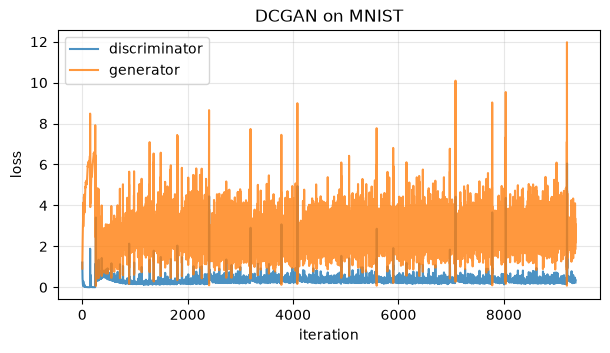

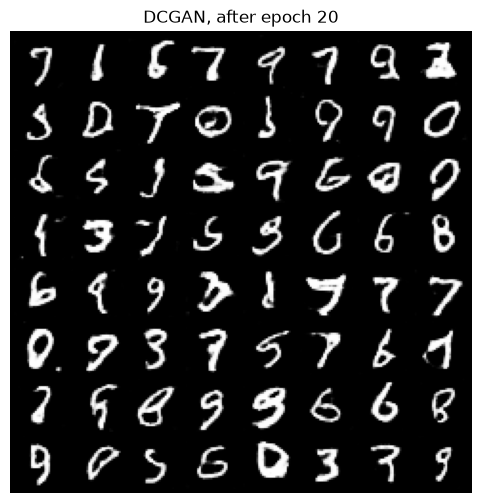

In [9]:
n_epochs_dc = 20 if device.type == "cuda" else 3     # increase it if you have a GPU (20 or more)
history_dc = train_gan(G_dc, D_dc, train_loader, n_epochs_dc, z_dim)
plot_losses(history_dc, "DCGAN on MNIST")
show_images(history_dc["samples"][-1], title=f"DCGAN, after epoch {n_epochs_dc}", size=6)

The function `train_gan` is reused without any change: it does not depend on the architecture.

After only 3 epochs the background is clean and the strokes are continuous: the convolutions learn local patterns (edges, strokes) much faster than the linear layers. Some digits are still badly formed; with 20 epochs or more they become very good.

**Question 1.1.** Why do we call `.detach()` on the fake images in Phase 1, and not in Phase 2?

**Question 1.2.** In Phase 2, the fake images get the target 1. Explain why. What would happen with the target 0?

**Question 1.3.** Look at the loss curves. Do they go down like the loss of a classifier? Why?

**Question 1.4.** The generator never sees a real image. How does it learn to draw digits?

**Question 1.5.** Compare the images of the linear GAN and of the DCGAN. Count the parameters of each generator.

**Question 1.6.** *(Exercise)* Remove `Normalize` from the transform (pixels in $[0, 1]$) and train the linear GAN again for 2 epochs. What happens? Why?

*Your answers:*

In [10]:
# Question 1.5: parameters of each generator
print("Linear generator:", sum(p.numel() for p in G.parameters()))
print("DCGAN generator :", sum(p.numel() for p in G_dc.parameters()))

Linear generator: 559632
DCGAN generator : 778305


Epoch  1/2 | loss D: 0.924 | loss G: 2.229
Epoch  2/2 | loss D: 1.009 | loss G: 3.122
without Normalize: real mean 0.13, fake mean 0.13 | fake pixels below 0: 35.0% | D accuracy: real 60.9%, fake 93.8%


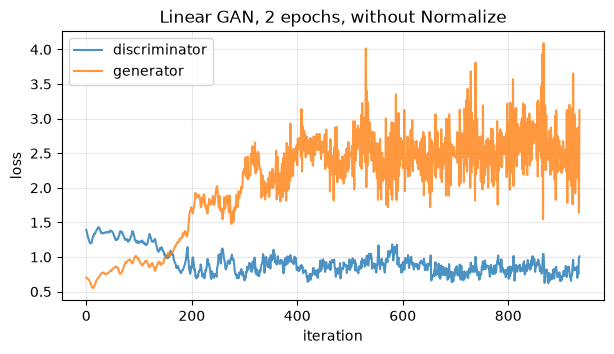

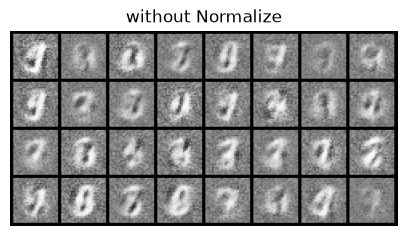

Epoch  1/2 | loss D: 0.465 | loss G: 1.707
Epoch  2/2 | loss D: 0.673 | loss G: 2.854
with Normalize: real mean -0.74, fake mean -0.66 | fake pixels below 0: 87.4% | D accuracy: real 65.6%, fake 100.0%


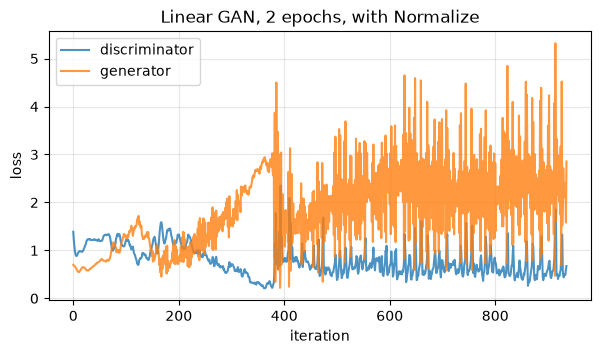

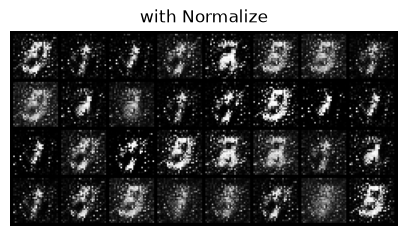

In [11]:
# Question 1.6: train the linear GAN for 2 epochs, without and with Normalize (same seed)
raw_data = datasets.MNIST(root="data", train=True, download=True, transform=transforms.ToTensor())
raw_loader = torch.utils.data.DataLoader(raw_data, batch_size=batch_size, shuffle=True, drop_last=True)

for name, loader in [("without Normalize", raw_loader), ("with Normalize", train_loader)]:
    torch.manual_seed(0)
    G_q, D_q = Generator(z_dim).to(device), Discriminator().to(device)
    history_q = train_gan(G_q, D_q, loader, 2, z_dim)
    with torch.no_grad():
        real = next(iter(loader))[0].to(device)
        fake = G_q(torch.randn(len(real), z_dim, device=device))
        print(f"{name}: real mean {real.mean():.2f}, fake mean {fake.mean():.2f} | "
              f"fake pixels below 0: {(fake < 0).float().mean():.1%} | "
              f"D accuracy: real {(D_q(real) > 0).float().mean():.1%}, "
              f"fake {(D_q(fake) < 0).float().mean():.1%}")
    plot_losses(history_q, f"Linear GAN, 2 epochs, {name}")
    show_images(history_q["samples"][-1][:32], title=name, size=5)

### Answers (Section 1)

**1.1.** In Phase 1 we train only $D$, so the fake images are simple inputs. `.detach()` cuts them from the graph of $G$: `loss_d.backward()` does not compute gradients for $G$, which would be useless work (and would push $G$ to *help* $D$ if they were applied). In Phase 2, $G$ can learn only from the gradient that goes from the output of $D$, through the fake image, into its weights. With `.detach()` there, $G$ would get no gradient and would never change.

**1.2.** The target 1 means "I want $D$ to say *real*". The loss $-\log D(G(z))$ is small when $D$ is fooled, so minimizing it makes the fakes more convincing. It also gives a strong gradient when $D$ easily rejects the fakes. With the target 0, the loss would be $-\log(1 - D(G(z)))$: $G$ would be rewarded when its images are detected as fake. The two networks would cooperate, both losses would fall towards 0, and $G$ would produce obvious noise instead of digits.

**1.3.** No, they oscillate. A classifier minimizes a fixed objective. Here the objective of each network changes every time the other one is updated: progress of one increases the loss of the other.
- If $D$ could not separate real from fake ($D(x) = 0.5$), we would have $L_D = 2\ln 2 \approx 1.39$ and $L_G = \ln 2 \approx 0.69$.
- The linear GAN moves in this direction: in the last epochs $L_D$ is about 1.0 and $L_G$ about 1.3.
- In the DCGAN, $D$ stays ahead ($L_D$ about 0.3, $L_G$ about 3), although its digits are much better. So the loss of a GAN does not measure the quality of the images.

**1.4.** It learns through $D$. $D$ sees real images, so its weights encode what separates real from fake. In Phase 2, backpropagation gives $G$ the gradient $\partial L_G / \partial G(z)$: for each pixel, the direction of change that makes the image look more real to $D$. $G$ then moves its weights in this direction.

**1.5.**

| | Linear GAN | DCGAN |
|---|---|---|
| parameters of $G$ | 559 632 | 778 305 |
| epochs | 30 | 20 |
| images | recognizable digits, but isolated white pixels and broken strokes | clean background, continuous and sharp strokes, a few malformed digits |

The DCGAN has about 39 % more parameters, but 81 % of them (633 472) are in the first linear layer. The two transposed convolutions need only 132 161. They are better with few weights because they share them over the image and use the fact that neighbouring pixels are related.

**1.6.** Without `Normalize`, the real pixels are in $[0, 1]$ while the Tanh can give values in $[-1, 1]$.
- $G$ must learn to put the background at 0, in the middle of the Tanh, where its output varies quickly with its input: a small error gives visible noise. With `Normalize` the background is $-1$, where the Tanh saturates, so a clean background is easy.
- After 2 epochs, 35 % of the fake pixels are still negative. These values are impossible in a real image, so they are a possible clue for $D$.
- In this run $D$ does **not** win at once. $G$ learns the correct mean (0.13 for real and for fake), and $D$ detects 94 % of the fakes, against 100 % with `Normalize`. The digit shapes even look smoother.
- The grey background of the figure comes partly from the display: `show_images` maps $[-1, 1]$ to $[0, 1]$, so 0 is shown in grey. The noise on this background is real.

So the wrong range is a handicap for the quality of the images, but 2 epochs of this small network are not enough to make training collapse.

# Exercise A — The same work on Pokémon images

**Goal.** Do the work of Section 1 on a real colour dataset: train a DCGAN on images of Pokémon, at 64 × 64 pixels.

**Dataset.** *Pokémon Images Dataset*, <https://www.kaggle.com/datasets/kvpratama/pokemon-images-dataset>. It contains 819 images, each in two versions: PNG with a transparent background, and JPG on a white background (about 40 MB).

> **GAN or conditional GAN?** A conditional GAN needs a label for every training image. This dataset contains only images: no class, no type, no name (the files are just numbered). So we train a normal (unconditional) DCGAN here. The conditional GAN on colour images is Exercise B.

## A.1 Get the dataset
**On a PC or on Colab.** Run Section 1.1 and the function `train_gan` of 1.4 first, then:

In [12]:
import kagglehub

# PC / Colab: downloads the dataset once (about 40 MB) and returns the local folder.
# Kaggle: add the dataset with "Add Input" (right panel); the same line returns its folder.
path = kagglehub.dataset_download("kvpratama/pokemon-images-dataset")
print("Path to dataset files:", path)

Path to dataset files: /home/asura/.cache/kagglehub/datasets/kvpratama/pokemon-images-dataset/versions/2


`kagglehub.dataset_download` downloads the dataset the first time, then reuses the local copy (in a cache folder of your home directory). It returns the path of that folder. The dataset is public: no Kaggle account is needed. If a message asks you to log in, create a token on <https://www.kaggle.com/settings> (*API → Create New Token*) and follow the message.

**On Kaggle.** Open your notebook, then in the right panel: *Add Input → Datasets →* search "pokemon images dataset" (author kvpratama) *→ Add*. The files appear under `/kaggle/input/`, without any download. The code above works too: it returns the folder of the dataset.

**Without kagglehub.** Click *Download* on the page of the dataset, unzip the file in the folder of your notebook, and write `path = "pokemon-images-dataset"` (the name of the unzipped folder).

## A.2 Work to do
1. **Load the images.** Find all the image files with `glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)` (the folder is not the same on a PC, on Colab and on Kaggle). If you use the PNG files, put each image on a white background first (`Image.alpha_composite`). Resize the images to 64 × 64 (`Image.BICUBIC`).
2. **Build a `Dataset`** that keeps the 819 images in memory and returns pairs `(image, 0)`: `train_gan` expects a label, which it ignores. Use `RandomHorizontalFlip()`, `ToTensor()` and a `Normalize` with 3 values (one per channel). Use a `DataLoader` with `batch_size=32, shuffle=True, drop_last=True`. Show 32 real images with `show_images`.
3. **Build the DCGAN** of the table below, with `ngf = ndf = 32` on a CPU (64 on a GPU), and initialize all weights with $\mathcal{N}(0, 0.02)$ (DCGAN paper). Check the shapes: the generator must return `(B, 3, 64, 64)` and the discriminator `(B, 1)`.
4. **Train** with the function `train_gan` of Section 1, without any change: 150 epochs on a CPU, 500 or more on a GPU. Draw the losses.
5. **Show** the generated images after 10 epochs, 50 epochs and at the end (`history["samples"]`).
6. **Check if the generator copies its training images:** for 6 generated images, find the closest real image (smallest pixel distance, `torch.cdist`) and show the two rows.

| Generator | | Discriminator | |
|---|---|---|---|
| $z$ (seen as an image) | 100 × 1 × 1 | image | 3 × 64 × 64 |
| ConvT(k=4, s=1, p=0) | 8·ngf × 4 × 4 | Conv(k=4, s=2, p=1) | ndf × 32 × 32 |
| ConvT(k=4, s=2, p=1) | 4·ngf × 8 × 8 | Conv(k=4, s=2, p=1) | 2·ndf × 16 × 16 |
| ConvT(k=4, s=2, p=1) | 2·ngf × 16 × 16 | Conv(k=4, s=2, p=1) | 4·ndf × 8 × 8 |
| ConvT(k=4, s=2, p=1) | ngf × 32 × 32 | Conv(k=4, s=2, p=1) | 8·ndf × 4 × 4 |
| ConvT(k=4, s=2, p=1), Tanh | 3 × 64 × 64 | Conv(k=4, s=1, p=0) | 1 × 1 × 1 |

Each transposed convolution with $k=4$, $s=2$, $p=1$ doubles the size; the first one ($k=4$, $s=1$, $p=0$) turns $z$, seen as a 1 × 1 image with 100 channels, into a 4 × 4 map: $(1-1)\times 1 - 0 + 4 = 4$. The discriminator does the opposite. Use `bias=False` before a BatchNorm, BatchNorm in both networks (not on the output of $G$ nor on the input of $D$), ReLU in $G$, LeakyReLU(0.2) in $D$, Tanh at the end of $G$.

In [13]:
# A.2 — 1. Load the images
import glob
from PIL import Image

# the JPG files are already on a white background
files = sorted(glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True))
pokemon_images = []
for f in files:
    with Image.open(f) as img:
        pokemon_images.append(img.convert("RGB").resize((64, 64), Image.BICUBIC))
print(len(pokemon_images), "images of size", pokemon_images[0].size)

819 images of size (64, 64)


One batch: (32, 3, 64, 64) | values between -1.0 and 1.0


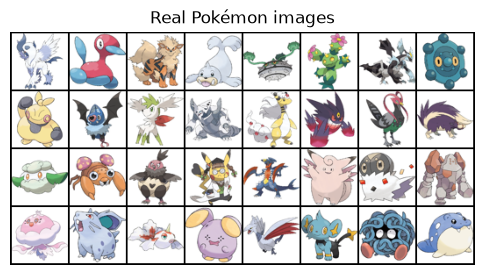

In [14]:
# A.2 — 2. Dataset, transforms, DataLoader (batch_size=32), show 32 real images
class PokemonDataset(torch.utils.data.Dataset):
    def __init__(self, images, transform):
        self.images = images
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(self.images[i]), 0    # dummy label, ignored by train_gan


pokemon_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
pokemon_data = PokemonDataset(pokemon_images, pokemon_transform)
pokemon_loader = torch.utils.data.DataLoader(pokemon_data, batch_size=32, shuffle=True, drop_last=True)

images, _ = next(iter(pokemon_loader))
print("One batch:", tuple(images.shape), "| values between", images.min().item(), "and", images.max().item())
show_images(images, title="Real Pokémon images")

In [15]:
# A.2 — 3. DCGAN (ngf = ndf = 32 on CPU, 64 on GPU), N(0, 0.02) initialization, shape check
ngf = ndf = 64 if device.type == "cuda" else 32


def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)    # a scale factor: centred on 1, not on 0
        nn.init.zeros_(m.bias)


class PokemonGenerator(nn.Module):
    def __init__(self, z_dim=100, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 8 * ngf, 4, 1, 0, bias=False),       # 1 -> 4
            nn.BatchNorm2d(8 * ngf), nn.ReLU(),
            nn.ConvTranspose2d(8 * ngf, 4 * ngf, 4, 2, 1, bias=False),     # 4 -> 8
            nn.BatchNorm2d(4 * ngf), nn.ReLU(),
            nn.ConvTranspose2d(4 * ngf, 2 * ngf, 4, 2, 1, bias=False),     # 8 -> 16
            nn.BatchNorm2d(2 * ngf), nn.ReLU(),
            nn.ConvTranspose2d(2 * ngf, ngf, 4, 2, 1, bias=False),         # 16 -> 32
            nn.BatchNorm2d(ngf), nn.ReLU(),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1),                           # 32 -> 64
            nn.Tanh())

    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))


class PokemonDiscriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1),                                    # 64 -> 32
            nn.LeakyReLU(0.2),
            nn.Conv2d(ndf, 2 * ndf, 4, 2, 1, bias=False),                  # 32 -> 16
            nn.BatchNorm2d(2 * ndf), nn.LeakyReLU(0.2),
            nn.Conv2d(2 * ndf, 4 * ndf, 4, 2, 1, bias=False),              # 16 -> 8
            nn.BatchNorm2d(4 * ndf), nn.LeakyReLU(0.2),
            nn.Conv2d(4 * ndf, 8 * ndf, 4, 2, 1, bias=False),              # 8 -> 4
            nn.BatchNorm2d(8 * ndf), nn.LeakyReLU(0.2),
            nn.Conv2d(8 * ndf, 1, 4, 1, 0),                                # 4 -> 1
            nn.Flatten())

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
G_p = PokemonGenerator(z_dim, ngf).to(device)
D_p = PokemonDiscriminator(ndf).to(device)
G_p.apply(weights_init)
D_p.apply(weights_init)

z = torch.randn(4, z_dim, device=device)
print("generator output    :", tuple(G_p(z).shape))
print("discriminator output:", tuple(D_p(G_p(z)).shape))

generator output    : (4, 3, 64, 64)
discriminator output: (4, 1)


Epoch  1/500 | loss D: 0.008 | loss G: 7.726
Epoch  2/500 | loss D: 0.001 | loss G: 19.441
Epoch  3/500 | loss D: 0.081 | loss G: 12.938
Epoch  4/500 | loss D: 0.892 | loss G: 2.164
Epoch  5/500 | loss D: 0.319 | loss G: 7.876
Epoch  6/500 | loss D: 0.252 | loss G: 6.533
Epoch  7/500 | loss D: 1.070 | loss G: 15.556
Epoch  8/500 | loss D: 0.200 | loss G: 5.124
Epoch  9/500 | loss D: 1.516 | loss G: 11.905
Epoch 10/500 | loss D: 0.296 | loss G: 7.605
Epoch 11/500 | loss D: 0.450 | loss G: 3.303
Epoch 12/500 | loss D: 0.739 | loss G: 3.206
Epoch 13/500 | loss D: 0.311 | loss G: 5.119
Epoch 14/500 | loss D: 0.168 | loss G: 5.521
Epoch 15/500 | loss D: 0.311 | loss G: 5.037
Epoch 16/500 | loss D: 0.194 | loss G: 3.112
Epoch 17/500 | loss D: 0.120 | loss G: 5.445
Epoch 18/500 | loss D: 0.920 | loss G: 10.150
Epoch 19/500 | loss D: 0.523 | loss G: 5.875
Epoch 20/500 | loss D: 1.377 | loss G: 6.585
Epoch 21/500 | loss D: 0.391 | loss G: 6.658
Epoch 22/500 | loss D: 3.619 | loss G: 8.200
Epoch

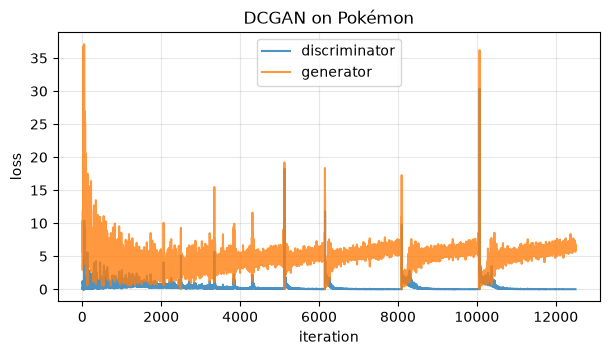

In [16]:
# A.2 — 4. Training with train_gan (150 epochs on CPU, 500+ on GPU), plot the losses
n_epochs_p = 500 if device.type == "cuda" else 150
history_p = train_gan(G_p, D_p, pokemon_loader, n_epochs_p, z_dim)
plot_losses(history_p, "DCGAN on Pokémon")

# train_gan keeps 64 colour images per epoch (about 1.5 GB for 500 epochs): keep only those we show
history_p["samples"] = {e: history_p["samples"][e - 1]
                        for e in (10, 50, n_epochs_p) if e <= n_epochs_p}

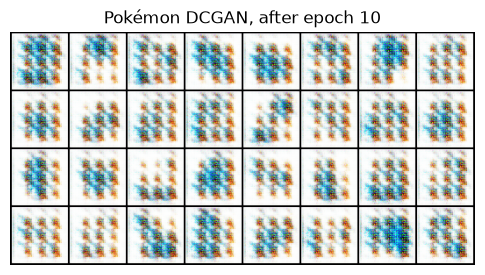

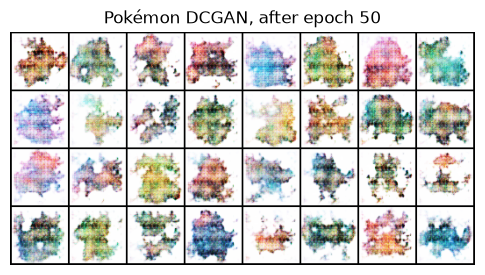

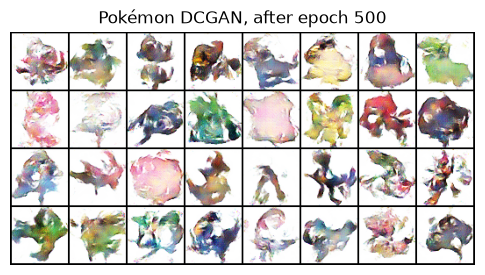

In [17]:
# A.2 — 5. Generated images after 10 epochs, 50 epochs and at the end (history["samples"])
for epoch, samples in history_p["samples"].items():
    show_images(samples[:32], title=f"Pokémon DCGAN, after epoch {epoch}")

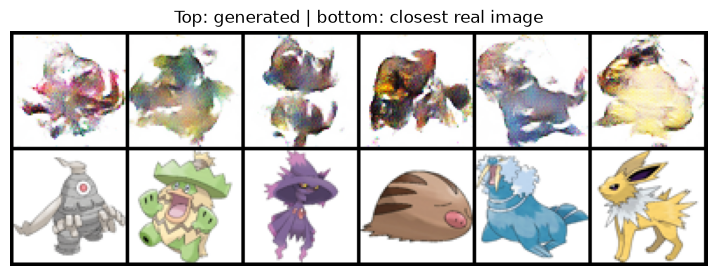

Distance to the closest real image, 6 generated: [45.5, 48.2, 48.5, 55.3, 50.7, 47.2]
64 generated       -> closest real      : median 47.2, min 24.5
819 real images -> closest other real: median 47.3, min 8.8


In [18]:
# A.2 — 6. Closest real image (torch.cdist) for 6 generated images
to_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
real_p = torch.stack([to_tensor(img) for img in pokemon_images])
real_both = torch.cat([real_p, real_p.flip(3)])     # G also saw the flipped images
fake_p = history_p["samples"][n_epochs_p]

distances = torch.cdist(fake_p.flatten(1), real_both.flatten(1))
closest = distances.argmin(dim=1)
show_images(torch.cat([fake_p[:6], real_both[closest[:6]]]), nrow=6, size=9,
            title="Top: generated | bottom: closest real image")

# reference: how far is a real image from the closest OTHER real image?
n = len(real_p)
real_distances = torch.cdist(real_p.flatten(1), real_both.flatten(1))
real_distances[torch.arange(n), torch.arange(n)] = float("inf")         # itself
real_distances[torch.arange(n), torch.arange(n) + n] = float("inf")     # its own mirror
print("Distance to the closest real image, 6 generated:",
      [round(d, 1) for d in distances.min(dim=1).values[:6].tolist()])
print(f"64 generated       -> closest real      : median {distances.min(1).values.median():.1f}, "
      f"min {distances.min():.1f}")
print(f"{n} real images -> closest other real: median {real_distances.min(1).values.median():.1f}, "
      f"min {real_distances.min():.1f}")

## Questions (Exercise A)

**Question A.1.** Why can we not train a conditional GAN on this dataset? What would we need?

**Question A.2.** What happens to the transparent background if we use `Image.open(f).convert("RGB")` directly on the PNG files? Try it.

**Question A.3.** Compute the number of updates of $G$ in the MNIST GAN (Section 1.5) and in this exercise. Explain why we need many more epochs here.

**Question A.4.** Look at the images after 10, 50 and `n_epochs_p` epochs. What does the generator learn first?

**Question A.5.** Look at the test "closest real image". Does the generator copy the training images?

*Your answers:*

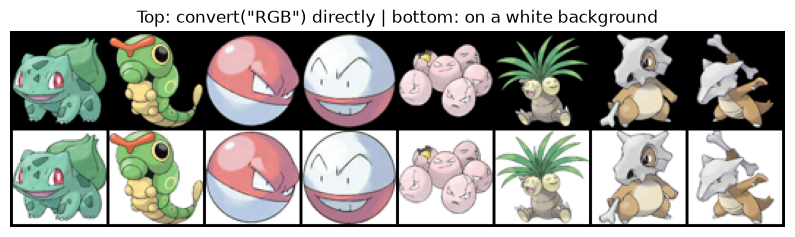

RGB values stored under the transparent pixels: [[0, 0, 0]]


In [19]:
# Question A.2: convert("RGB") directly, or put the PNG on a white background first
png_files = sorted(glob.glob(os.path.join(path, "**", "*.png"), recursive=True))[:8]
direct, on_white = [], []
for f in png_files:
    rgba = Image.open(f).convert("RGBA")
    white = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
    direct.append(to_tensor(rgba.convert("RGB").resize((64, 64), Image.BICUBIC)))
    on_white.append(to_tensor(Image.alpha_composite(white, rgba).convert("RGB").resize((64, 64), Image.BICUBIC)))
show_images(torch.stack(direct + on_white), nrow=8, size=10,
            title='Top: convert("RGB") directly | bottom: on a white background')

pixels = np.array(Image.open(png_files[0]).convert("RGBA"))
print("RGB values stored under the transparent pixels:",
      np.unique(pixels[pixels[..., 3] == 0][:, :3], axis=0)[:5].tolist())

In [20]:
# Question A.3: updates of G = number of batches per epoch x number of epochs
mnist_batches, pokemon_batches = len(train_loader), len(pokemon_loader)
print(f"MNIST  : {mnist_batches} batches x {n_epochs} epochs = {mnist_batches * n_epochs} updates")
print(f"Pokémon: {pokemon_batches} batches x {n_epochs_p} epochs = {pokemon_batches * n_epochs_p} updates")

MNIST  : 468 batches x 30 epochs = 14040 updates
Pokémon: 25 batches x 500 epochs = 12500 updates


### Answers (Exercise A)

**A.1.** A cGAN gives a class $y$ to both networks, and $D$ must see real images with their true class. This dataset has no class. We would need a label for each image, for example the type (fire, water, grass...) from a table that links the file number to the type, with enough images per class.

**A.2.** The background becomes **black**. `convert("RGB")` only deletes the alpha channel, and the RGB values stored under the transparent pixels are `[0, 0, 0]`. The GAN would learn black backgrounds, and dark outlines would disappear into them. `Image.alpha_composite` on a white image first gives the correct result.

**A.3.** The number of updates is the number of batches per epoch times the number of epochs.

| | batches per epoch | epochs (GPU, this run) | updates | epochs (CPU values) | updates |
|---|---|---|---|---|---|
| MNIST | $\lfloor 60000/128 \rfloor = 468$ | 30 | 14 040 | 5 | 2 340 |
| Pokémon | $\lfloor 819/32 \rfloor = 25$ | 500 | 12 500 | 150 | 3 750 |

One MNIST epoch gives about 19 times more updates than one Pokémon epoch. The networks learn per update, not per epoch, so a small dataset needs many more epochs. The images are also harder here: 12 288 values instead of 784.

**A.4.** It learns from global to local.
- **10 epochs:** the white background and a centred region. The images are almost all the same blue and orange grid of blobs, an artifact of the transposed convolutions.
- **50 epochs:** varied colours and silhouettes, one creature in the centre, still with a strong grid texture.
- **500 epochs:** much sharper outlines, body-like shapes, shading. There are still no real faces or anatomy: the images look like Pokémon only from far away.

The loss curves show a limit: in the second half $L_D$ is near 0 most of the time (with a few sudden spikes) and $L_G$ slowly grows. With only 819 images $D$ can memorize the training set and win. More data or more augmentation would probably help more than more epochs.

**A.5.** There is no sign of copying. The closest real images share the rough silhouette or the dominant colour, but they are clearly different creatures. The median distance from a generated image to its closest real image is 47.2, the same as between two different real images (47.3), and the minimum is 24.5. A copy would have a distance near 0. This test compares pixels, so it would not detect a shifted or recoloured copy.

# Section 2 — A conditional GAN (cGAN) on MNIST

**Goal.** The GAN of Section 1 draws a *random* digit: we cannot choose which one. A conditional GAN receives an extra input $y$, the class (here, the digit 0 to 9):

$$G(z, y) \to \text{an image of class } y, \qquad D(x, y) \to \text{"is } x \text{ a real image of class } y\text{?"}$$

The discriminator now rejects two kinds of fakes: images that do not look real, and real-looking images that do not match their label. So the generator must respect the class.

## 2.1 Imports, helpers and data
The block of 1.1 (imports, `show_images`, `plot_losses`) is the same. The data are the same as in 1.2, but now we keep the labels:

In [21]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True,
                                           drop_last=True)
n_classes = 10
z_dim = 100

## 2.2 The two networks

In [22]:
class CondGenerator(nn.Module):
    def __init__(self, z_dim=100, n_classes=10, emb_dim=10):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, emb_dim)      # class number -> small vector
        self.fc = nn.Sequential(nn.Linear(z_dim + emb_dim, 128 * 7 * 7),
                                nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),   # 7 -> 14
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1),     # 14 -> 28
            nn.Tanh())

    def forward(self, z, y):
        h = torch.cat([z, self.label_emb(y)], dim=1)   # join the noise and the label vector
        x = self.fc(h).view(-1, 128, 7, 7)
        return self.net(x)


class CondDiscriminator(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        # the label becomes a full 28 x 28 map, added to the image as a second channel
        self.label_emb = nn.Embedding(n_classes, 28 * 28)
        self.net = nn.Sequential(
            nn.Conv2d(2, 64, 4, stride=2, padding=1),          # 2 channels: image + label
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1))

    def forward(self, x, y):
        label_map = self.label_emb(y).view(-1, 1, 28, 28)
        h = torch.cat([x, label_map], dim=1)   # join image and label map (channel axis)
        return self.net(h)


torch.manual_seed(0)
G_c = CondGenerator(z_dim, n_classes).to(device)
D_c = CondDiscriminator(n_classes).to(device)

z = torch.randn(4, z_dim, device=device)
y = torch.tensor([0, 1, 2, 3], device=device)
print("generator output    :", tuple(G_c(z, y).shape))
print("discriminator output:", tuple(D_c(G_c(z, y), y).shape))

generator output    : (4, 1, 28, 28)
discriminator output: (4, 1)


- `nn.Embedding(10, 10)` is a table of 10 learnable vectors: the class number `y` selects its row. It is a learned version of the one-hot vector.
- **Generator:** the noise (100) and the label vector (10) are joined with `torch.cat(..., dim=1)` into one vector of 110 numbers. The rest is the DCGAN generator of 1.7.
- **Discriminator:** an image has a shape 1×28×28, a label vector does not. So the label is turned into a full 28 × 28 map (`Embedding(10, 784)`, then `view`) and added as a second channel: the first `Conv2d` has 2 input channels. `dim=1` is the channel axis of a batch (B, C, H, W).

Expected output:
```
generator output    : (4, 1, 28, 28)
discriminator output: (4, 1)
```

## 2.3 Training

In [23]:
criterion = nn.BCEWithLogitsLoss()


def train_cgan(G, D, loader, n_epochs, z_dim, n_classes, lr=2e-4):
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    history = {"d": [], "g": []}

    for epoch in range(1, n_epochs + 1):
        G.train(); D.train()
        for real, labels in loader:                    # now the labels ARE used
            real, labels = real.to(device), labels.to(device)
            B = real.size(0)
            ones = torch.ones(B, 1, device=device)
            zeros = torch.zeros(B, 1, device=device)

            # ---------- Phase 1: discriminator ----------
            z = torch.randn(B, z_dim, device=device)
            # random classes for the fake images
            fake_labels = torch.randint(0, n_classes, (B,), device=device)
            fake = G(z, fake_labels).detach()
            loss_d = (criterion(D(real, labels), ones)          # true labels
                      + criterion(D(fake, fake_labels), zeros))  # labels given to G
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

            # ---------- Phase 2: generator ----------
            z = torch.randn(B, z_dim, device=device)
            fake_labels = torch.randint(0, n_classes, (B,), device=device)
            loss_g = criterion(D(G(z, fake_labels), fake_labels), ones)   # fake image AND its class must look real
            opt_g.zero_grad()
            loss_g.backward()
            opt_g.step()

            history["d"].append(loss_d.item())
            history["g"].append(loss_g.item())

        print(f"Epoch {epoch:2d}/{n_epochs} | loss D: {loss_d.item():.3f} "
              f"| loss G: {loss_g.item():.3f}")
    return history

- The loop is the loop of 1.4, with the labels added to every call of $G$ and $D$.
- Real images come with their **true labels**. Fake images get **random labels** (`torch.randint`): the generator must learn every class.
- In Phase 2, the discriminator receives the fake image and the label that was asked. If the image is a nice "3" but the label was "8", $D$ answers "fake", and $G$ is pushed to draw an "8".

Epoch  1/20 | loss D: 0.893 | loss G: 1.428
Epoch  2/20 | loss D: 0.683 | loss G: 1.162
Epoch  3/20 | loss D: 0.551 | loss G: 1.213
Epoch  4/20 | loss D: 0.788 | loss G: 1.343
Epoch  5/20 | loss D: 0.708 | loss G: 1.595
Epoch  6/20 | loss D: 0.850 | loss G: 1.202
Epoch  7/20 | loss D: 0.986 | loss G: 1.195
Epoch  8/20 | loss D: 0.706 | loss G: 2.393
Epoch  9/20 | loss D: 0.624 | loss G: 1.123
Epoch 10/20 | loss D: 0.893 | loss G: 1.451
Epoch 11/20 | loss D: 1.024 | loss G: 0.901
Epoch 12/20 | loss D: 0.891 | loss G: 1.479
Epoch 13/20 | loss D: 1.095 | loss G: 0.640
Epoch 14/20 | loss D: 0.970 | loss G: 1.687
Epoch 15/20 | loss D: 1.399 | loss G: 1.253
Epoch 16/20 | loss D: 1.343 | loss G: 0.574
Epoch 17/20 | loss D: 0.936 | loss G: 0.638
Epoch 18/20 | loss D: 1.159 | loss G: 1.423
Epoch 19/20 | loss D: 0.626 | loss G: 2.095
Epoch 20/20 | loss D: 0.697 | loss G: 1.180


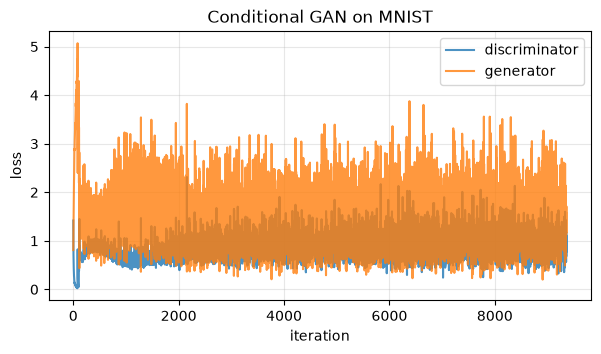

In [24]:
n_epochs = 20 if device.type == "cuda" else 3        # increase it if you have a GPU (20 or more)
history_c = train_cgan(G_c, D_c, train_loader, n_epochs, z_dim, n_classes)
plot_losses(history_c, "Conditional GAN on MNIST")

Expected output:
```
Epoch 1/3 | loss D: 0.844 | loss G: 1.552
Epoch 2/3 | loss D: 0.835 | loss G: 1.022
Epoch 3/3 | loss D: 0.990 | loss G: 0.618
```

## 2.4 One row per class

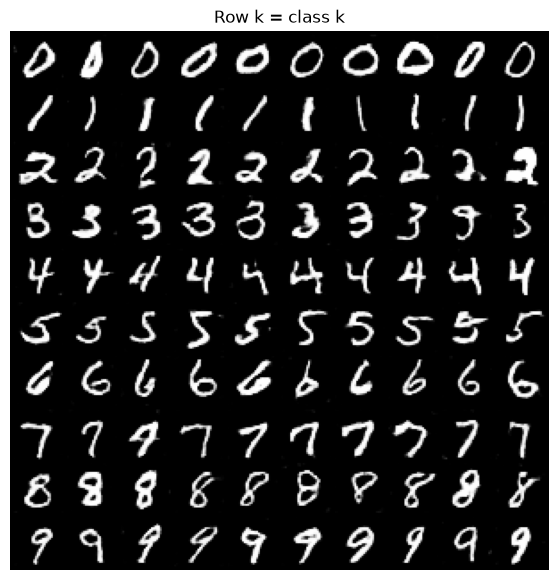

In [25]:
def class_grid(G, n_classes, z_dim, n_per_class=10):
    # one row per class: row k contains n_per_class images of class k
    G.eval()
    with torch.no_grad():
        y = torch.arange(n_classes, device=device).repeat_interleave(n_per_class)
        z = torch.randn(n_classes * n_per_class, z_dim, device=device)
        return G(z, y)


torch.manual_seed(1)
show_images(class_grid(G_c, n_classes, z_dim), nrow=10, title="Row k = class k", size=7)

`repeat_interleave(10)` gives the labels 0,0,...,0,1,1,...,9: with `nrow=10`, row $k$ of the grid contains ten images generated with the label $k$, each with a different noise $z$.

## 2.5 Choose the digit

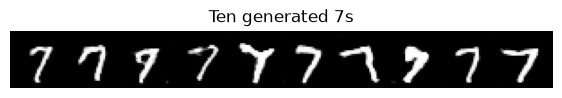

In [26]:
def generate_digit(G, digit, n=10):
    G.eval()
    with torch.no_grad():
        z = torch.randn(n, z_dim, device=device)
        y = torch.full((n,), digit, dtype=torch.long, device=device)   # n times the chosen class
        return G(z, y)


show_images(generate_digit(G_c, 7), nrow=10, title="Ten generated 7s", size=7)

`torch.full((n,), digit)` is a tensor of $n$ times the same label. This is what a cGAN gives: we ask for a "7", we get ten different "7"s.

## 2.6 Same noise, different classes

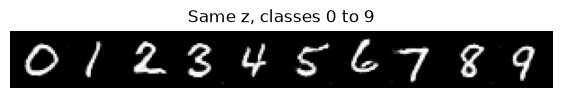

In [27]:
# the SAME noise z for every column, the class changes from 0 to 9:
# z controls the style (thickness, slant), y controls the digit
torch.manual_seed(2)
z = torch.randn(1, z_dim, device=device).repeat(10, 1)
y = torch.arange(10, device=device)
with torch.no_grad():
    G_c.eval()
    show_images(G_c(z, y), nrow=10, title="Same z, classes 0 to 9", size=7)

All ten images use the same $z$. The digits change, but they share the same *style* (thickness, slant, size). The label $y$ decides **what** is drawn; the noise $z$ decides **how** it is drawn.

**Question 2.1.** Why are the fake labels random, and not the labels of the real batch?

**Question 2.2.** What does the discriminator check in a cGAN that it does not check in a GAN?

**Question 2.3.** In 2.6, which properties of the digit are controlled by $z$? By $y$?

**Question 2.4.** *(Exercise)* Replace the `Embedding` of the generator by a one-hot vector (`F.one_hot(y, 10).float()`). Which line(s) must change? Does it still work?

**Question 2.5.** *(Exercise)* Train a small CNN classifier on MNIST and use it to check the generator: for 1 000 generated digits (100 per class), how often does the classifier find the class that we asked for?

*Your answers:*

Epoch  1/20 | loss D: 0.924 | loss G: 1.394
Epoch  2/20 | loss D: 0.520 | loss G: 2.332
Epoch  3/20 | loss D: 0.391 | loss G: 1.703
Epoch  4/20 | loss D: 0.550 | loss G: 1.288
Epoch  5/20 | loss D: 0.465 | loss G: 1.202
Epoch  6/20 | loss D: 0.758 | loss G: 1.510
Epoch  7/20 | loss D: 1.324 | loss G: 0.593
Epoch  8/20 | loss D: 0.586 | loss G: 2.311
Epoch  9/20 | loss D: 0.446 | loss G: 1.010
Epoch 10/20 | loss D: 0.408 | loss G: 0.892
Epoch 11/20 | loss D: 0.971 | loss G: 1.510
Epoch 12/20 | loss D: 0.582 | loss G: 1.431
Epoch 13/20 | loss D: 0.984 | loss G: 0.608
Epoch 14/20 | loss D: 0.772 | loss G: 1.658
Epoch 15/20 | loss D: 0.718 | loss G: 0.995
Epoch 16/20 | loss D: 0.950 | loss G: 0.820
Epoch 17/20 | loss D: 0.958 | loss G: 1.982
Epoch 18/20 | loss D: 0.656 | loss G: 0.889
Epoch 19/20 | loss D: 0.913 | loss G: 2.994
Epoch 20/20 | loss D: 0.592 | loss G: 1.602


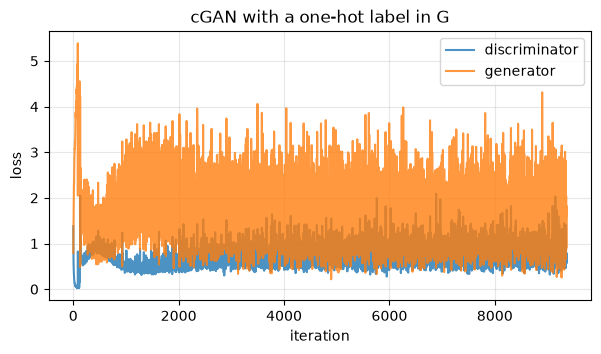

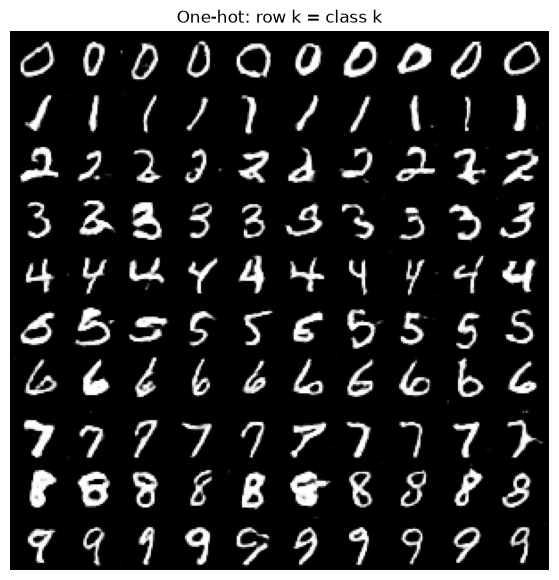

In [28]:
# Question 2.4: a one-hot vector instead of the Embedding of the generator
class OneHotGenerator(CondGenerator):
    def __init__(self, z_dim=100, n_classes=10):
        super().__init__(z_dim, n_classes, emb_dim=n_classes)   # fc input: z_dim + n_classes
        del self.label_emb                                      # changed line 1: no Embedding
        self.n_classes = n_classes

    def forward(self, z, y):
        h = torch.cat([z, F.one_hot(y, self.n_classes).float()], dim=1)     # changed line 2
        return self.net(self.fc(h).view(-1, 128, 7, 7))


torch.manual_seed(0)
G_onehot = OneHotGenerator(z_dim, n_classes).to(device)
D_onehot = CondDiscriminator(n_classes).to(device)
history_onehot = train_cgan(G_onehot, D_onehot, train_loader, n_epochs, z_dim, n_classes)
plot_losses(history_onehot, "cGAN with a one-hot label in G")
show_images(class_grid(G_onehot, n_classes, z_dim), nrow=10, title="One-hot: row k = class k", size=7)

In [29]:
# Question 2.5: a small CNN classifier checks the class of the generated digits
torch.manual_seed(0)
classifier = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 28 -> 14
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 14 -> 7
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

for epoch in range(3):
    classifier.train()
    for x, y in train_loader:
        loss = F.cross_entropy(classifier(x.to(device)), y.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

classifier.eval()
test_data = datasets.MNIST(root="data", train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=500)
with torch.no_grad():
    correct = sum((classifier(x.to(device)).argmax(1) == y.to(device)).sum().item() for x, y in test_loader)
    print(f"Classifier on real test digits: {correct / len(test_data):.2%}")

    y = torch.arange(n_classes, device=device).repeat_interleave(100)
    for name, model in [("Embedding", G_c), ("one-hot", G_onehot)]:
        torch.manual_seed(3)
        pred = classifier(class_grid(model, n_classes, z_dim, n_per_class=100)).argmax(1)
        print(f"Generated digits, {name:9s}: {(pred == y).float().mean():.1%} | per class:",
              [int((pred[y == k] == k).sum()) for k in range(n_classes)])

Classifier on real test digits: 98.76%
Generated digits, Embedding: 98.6% | per class: [100, 100, 99, 100, 98, 94, 100, 99, 100, 96]
Generated digits, one-hot  : 98.0% | per class: [100, 100, 99, 100, 100, 86, 100, 99, 98, 98]


### Answers (Section 2)

**2.1.** $G$ must be able to draw every class on request, independently of the current real batch, so we sample $y$ as we will at test time. `randint` gives each class the same probability, whereas MNIST is slightly unbalanced. The labels of the real batch would also work, as they follow the distribution of the data, but they are not necessary: there is no pairing between the $i$-th fake and the $i$-th real image. What matters is that $G$ and $D$ receive the **same** label for a given fake.

**2.2.** It checks that the image **matches its label**. A GAN asks "is $x$ real?", a cGAN asks "is $(x, y)$ a real pair?". A perfect "3" with the label 8 must be rejected, because this pair never appears in the real data. Our loop never shows such real mismatched pairs to $D$: it learns the matching because the real images always come with their correct labels.

**2.3.** $y$ controls the identity of the digit. $z$ controls the style: thickness, slant, width, roundness, small details of the writing. In 2.6 the ten digits have similar thin strokes and look written by the same hand. This separation was learned, it was not programmed.

**2.4.** Two lines change in `CondGenerator`:
1. in `__init__`, remove `self.label_emb = nn.Embedding(...)`;
2. in `forward`, use `h = torch.cat([z, F.one_hot(y, 10).float()], dim=1)`.

The first `Linear` does not change here, because `emb_dim` was already 10. With another `emb_dim`, its input would become `z_dim + 10`. It still works: 98.0 % of the digits have the requested class, against 98.6 % with the Embedding, too small a difference to conclude from one run. This is expected: a linear layer after a one-hot vector can itself learn one vector per class.

**2.5.** The classifier has 98.76 % accuracy on real test digits. It finds the requested class for **98.6 %** of the 1 000 generated digits (986), so the conditioning works very well. The weakest classes are 5 (94/100) and 9 (96/100). This score measures only the class: a generator that repeats one perfect image per digit would get 100 %, so we must also look at the diversity in the grid.

# Exercise B — A conditional GAN on flower photos

**Goal.** Do the work of Section 2 on colour photos: train a conditional GAN that draws the flower we ask for, at 64 × 64 pixels.

**Dataset.** *Flowers Recognition*, <https://www.kaggle.com/datasets/alxmamaev/flowers-recognition>. About 4 200 colour photos (about 230 MB) in 5 classes: daisy, dandelion, rose, sunflower, tulip. There is one folder per class: **the label of an image is the name of its folder**. The photos have different sizes.

## B.1 Get the dataset
**On a PC or on Colab.** Run Section 1.1, and the functions `train_cgan` (2.3) and `class_grid` (2.4) first, then:

In [30]:
import kagglehub

# PC / Colab: downloads the dataset once (about 230 MB) and returns the local folder.
# Kaggle: add the dataset with "Add Input" (right panel); the same line returns its folder.
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
print("Path to dataset files:", path)

Path to dataset files: /home/asura/.cache/kagglehub/datasets/alxmamaev/flowers-recognition/versions/2


**On Kaggle.** In the right panel: *Add Input → Datasets →* search "flowers recognition" (author alxmamaev) *→ Add*. The files appear under `/kaggle/input/`; the code above returns their folder.

**Without kagglehub.** Click *Download* on the page of the dataset, unzip the file in the folder of your notebook, and write `path = "flowers-recognition"`.

## B.2 Work to do
1. **Find the images and their labels.** Use the list `classes = ["daisy", "dandelion", "rose", "sunflower", "tulip"]`; the label of an image is the position of its folder name in this list. Search the files with `glob` (`recursive=True`) and keep only the image files (`.jpg`, `.png`). Some versions of the archive contain every image twice (`flowers/` and `flowers/flowers/`): keep each file name only once. Print the number of images of each class.
2. **Prepare the images.** Cut the largest centred square of each photo (`img.crop`), resize it to 64 × 64, and keep all the images in memory. The `Dataset` returns pairs `(image, label)`. Use `RandomHorizontalFlip()`, `ToTensor()`, `Normalize` with 3 values, and batches of 64.
3. **Build the conditional networks** by combining Section 2 and Exercise A:
   - *generator:* the noise (100) and an `Embedding(5, 50)` of the label are joined with `torch.cat`; the vector of 150 values is seen as a 150 × 1 × 1 image and goes through the five transposed convolutions of the Pokémon generator (1 → 4 → 8 → 16 → 32 → 64);
   - *discriminator:* the label becomes a 64 × 64 map (`Embedding(5, 64 * 64)`), joined to the RGB image as a fourth channel; then the five convolutions of the Pokémon discriminator, with 4 input channels.

   Use `ngf = ndf = 32` on a CPU (64 on a GPU) and the initialization $\mathcal{N}(0, 0.02)$. Check the output shapes.
4. **Train** with the function `train_cgan` of Section 2, without any change: 30 epochs on a CPU, 100 or more on a GPU. Draw the losses.
5. **Show one row per class** with `class_grid` (8 images per class), then write a function `generate_flower(G, name, n=8)` that generates `n` images of the class `name` (for example `"sunflower"`).

In [31]:
# B.2 — 1. Find the images and their labels
import glob
from PIL import Image

classes = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

flower_files, flower_labels, seen = [], [], set()
for f in sorted(glob.glob(os.path.join(path, "**", "*"), recursive=True)):
    folder, name = os.path.basename(os.path.dirname(f)), os.path.basename(f)
    if folder in classes and name.lower().endswith((".jpg", ".png")) and name not in seen:
        seen.add(name)
        flower_files.append(f)
        flower_labels.append(classes.index(folder))

for k, name in enumerate(classes):
    print(f"{name:10s}: {flower_labels.count(k)}")
print("total     :", len(flower_files))

daisy     : 764
dandelion : 1052
rose      : 784
sunflower : 733
tulip     : 980
total     : 4313


One batch: (64, 3, 64, 64) (64,)


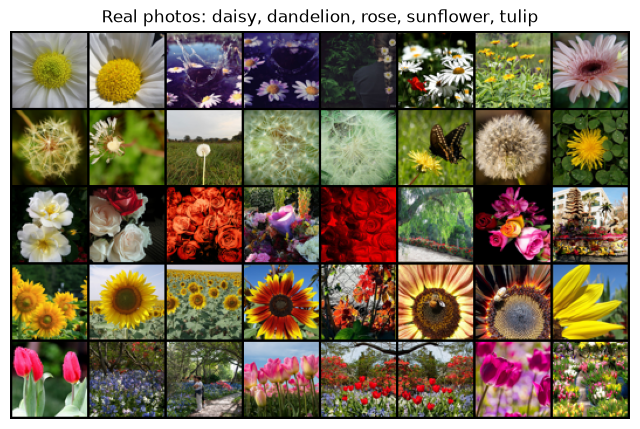

In [32]:
# B.2 — 2. Prepare the images (centred square crop, resize to 64 x 64), Dataset, DataLoader (batch 64)
def square_64(img):
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    return img.crop((left, top, left + side, top + side)).resize((64, 64), Image.BICUBIC)


class FlowerDataset(torch.utils.data.Dataset):
    def __init__(self, files, labels, transform):
        self.images = []
        for f in files:
            with Image.open(f) as img:
                self.images.append(square_64(img.convert("RGB")))
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(self.images[i]), self.labels[i]


flower_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
flower_data = FlowerDataset(flower_files, flower_labels, flower_transform)
flower_loader = torch.utils.data.DataLoader(flower_data, batch_size=64, shuffle=True, drop_last=True)

images, labels = next(iter(flower_loader))
print("One batch:", tuple(images.shape), tuple(labels.shape))
real_rows = [flower_data[flower_labels.index(k) + i][0] for k in range(len(classes)) for i in range(8)]
show_images(torch.stack(real_rows), nrow=8, title="Real photos: " + ", ".join(classes), size=8)

In [33]:
# B.2 — 3. Conditional generator and discriminator (ngf = ndf = 32 on CPU, 64 on GPU), N(0, 0.02) init, shape check
ngf = ndf = 64 if device.type == "cuda" else 32


def weights_init(m):
    # the embeddings keep N(0, 1), the same scale as z
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


class FlowerGenerator(nn.Module):
    def __init__(self, z_dim=100, n_classes=5, emb_dim=50, ngf=64):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, emb_dim)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim + emb_dim, 8 * ngf, 4, 1, 0, bias=False),     # 1 -> 4
            nn.BatchNorm2d(8 * ngf), nn.ReLU(),
            nn.ConvTranspose2d(8 * ngf, 4 * ngf, 4, 2, 1, bias=False),             # 4 -> 8
            nn.BatchNorm2d(4 * ngf), nn.ReLU(),
            nn.ConvTranspose2d(4 * ngf, 2 * ngf, 4, 2, 1, bias=False),             # 8 -> 16
            nn.BatchNorm2d(2 * ngf), nn.ReLU(),
            nn.ConvTranspose2d(2 * ngf, ngf, 4, 2, 1, bias=False),                 # 16 -> 32
            nn.BatchNorm2d(ngf), nn.ReLU(),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1),                                   # 32 -> 64
            nn.Tanh())

    def forward(self, z, y):
        h = torch.cat([z, self.label_emb(y)], dim=1)
        return self.net(h.view(h.size(0), -1, 1, 1))


class FlowerDiscriminator(nn.Module):
    def __init__(self, n_classes=5, ndf=64):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, 64 * 64)
        self.net = nn.Sequential(
            nn.Conv2d(4, ndf, 4, 2, 1),                                            # RGB + label
            nn.LeakyReLU(0.2),
            nn.Conv2d(ndf, 2 * ndf, 4, 2, 1, bias=False),                          # 32 -> 16
            nn.BatchNorm2d(2 * ndf), nn.LeakyReLU(0.2),
            nn.Conv2d(2 * ndf, 4 * ndf, 4, 2, 1, bias=False),                      # 16 -> 8
            nn.BatchNorm2d(4 * ndf), nn.LeakyReLU(0.2),
            nn.Conv2d(4 * ndf, 8 * ndf, 4, 2, 1, bias=False),                      # 8 -> 4
            nn.BatchNorm2d(8 * ndf), nn.LeakyReLU(0.2),
            nn.Conv2d(8 * ndf, 1, 4, 1, 0),                                        # 4 -> 1
            nn.Flatten())

    def forward(self, x, y):
        label_map = self.label_emb(y).view(-1, 1, 64, 64)
        return self.net(torch.cat([x, label_map], dim=1))


torch.manual_seed(0)
G_f = FlowerGenerator(z_dim, len(classes), ngf=ngf).to(device)
D_f = FlowerDiscriminator(len(classes), ndf).to(device)
G_f.apply(weights_init)
D_f.apply(weights_init)

z = torch.randn(4, z_dim, device=device)
y = torch.tensor([0, 1, 2, 3], device=device)
print("generator output    :", tuple(G_f(z, y).shape))
print("discriminator output:", tuple(D_f(G_f(z, y), y).shape))

generator output    : (4, 3, 64, 64)
discriminator output: (4, 1)


Epoch  1/100 | loss D: 0.474 | loss G: 5.966
Epoch  2/100 | loss D: 0.503 | loss G: 4.975
Epoch  3/100 | loss D: 1.349 | loss G: 7.018
Epoch  4/100 | loss D: 0.768 | loss G: 9.345
Epoch  5/100 | loss D: 1.015 | loss G: 5.472
Epoch  6/100 | loss D: 1.412 | loss G: 7.968
Epoch  7/100 | loss D: 0.543 | loss G: 7.456
Epoch  8/100 | loss D: 1.346 | loss G: 3.599
Epoch  9/100 | loss D: 0.501 | loss G: 2.593
Epoch 10/100 | loss D: 0.305 | loss G: 2.928
Epoch 11/100 | loss D: 0.470 | loss G: 1.181
Epoch 12/100 | loss D: 0.286 | loss G: 4.531
Epoch 13/100 | loss D: 0.775 | loss G: 2.358
Epoch 14/100 | loss D: 0.622 | loss G: 2.722
Epoch 15/100 | loss D: 0.802 | loss G: 2.219
Epoch 16/100 | loss D: 1.509 | loss G: 4.381
Epoch 17/100 | loss D: 1.011 | loss G: 1.664
Epoch 18/100 | loss D: 2.048 | loss G: 4.497
Epoch 19/100 | loss D: 0.837 | loss G: 2.115
Epoch 20/100 | loss D: 1.306 | loss G: 0.979
Epoch 21/100 | loss D: 0.647 | loss G: 1.396
Epoch 22/100 | loss D: 0.357 | loss G: 3.790
Epoch 23/1

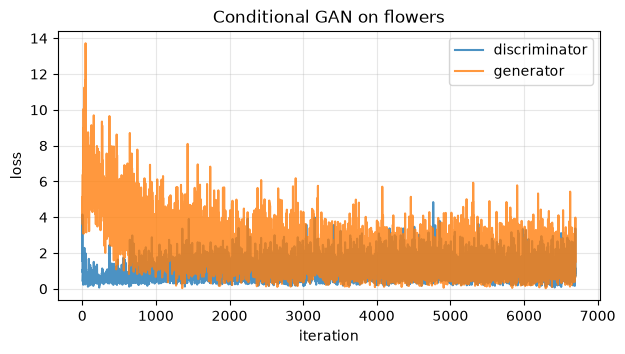

In [34]:
# B.2 — 4. Training with train_cgan (30 epochs on CPU, 100+ on GPU), plot the losses
n_epochs_f = 100 if device.type == "cuda" else 30
history_f = train_cgan(G_f, D_f, flower_loader, n_epochs_f, z_dim, len(classes))
plot_losses(history_f, "Conditional GAN on flowers")

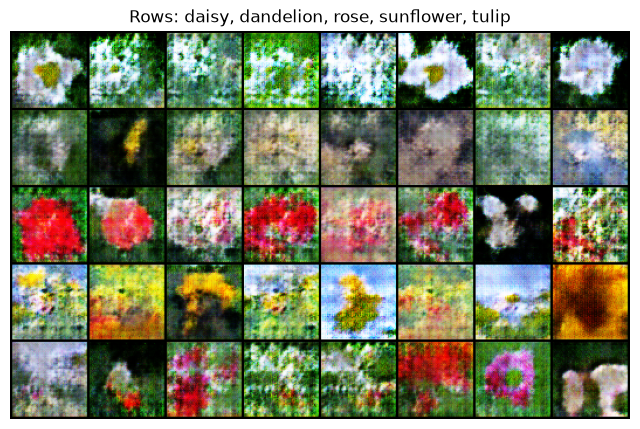

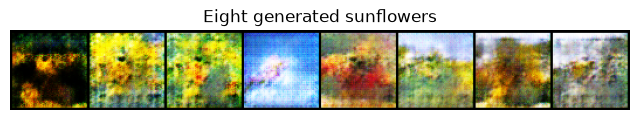

In [35]:
# B.2 — 5. One row per class with class_grid (8 per class), and generate_flower(G, name, n=8)
torch.manual_seed(1)
show_images(class_grid(G_f, len(classes), z_dim, n_per_class=8), nrow=8, size=8,
            title="Rows: " + ", ".join(classes))


def generate_flower(G, name, n=8):
    G.eval()
    with torch.no_grad():
        z = torch.randn(n, z_dim, device=device)
        y = torch.full((n,), classes.index(name), dtype=torch.long, device=device)
        return G(z, y)


show_images(generate_flower(G_f, "sunflower"), nrow=8, title="Eight generated sunflowers", size=8)

## Questions (Exercise B)

**Question B.1.** Why does the discriminator have 3 + 1 input channels?

**Question B.2.** Which rows of the grid are the easiest to recognize? Why?

**Question B.3.** Compare the difficulty of MNIST and of this dataset for a GAN.

**Question B.4.** *(Exercise)* Show the same noise $z$ with the five classes (as in 2.6). Is $z$ still a "style"?

*Your answers:*

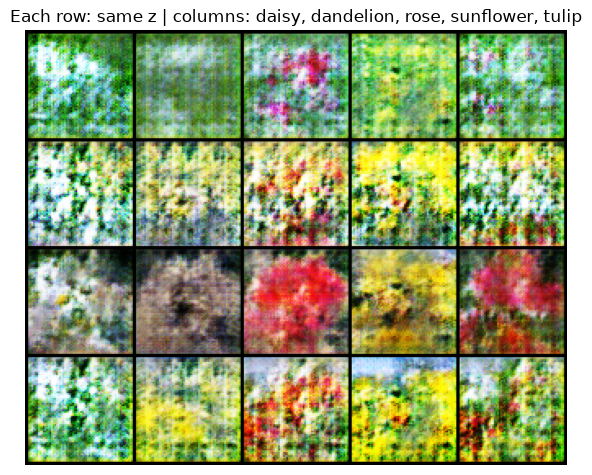

In [36]:
# Question B.4: the same noise z (one row) with the five classes (the columns)
torch.manual_seed(2)
n_styles = 4
z = torch.randn(n_styles, z_dim, device=device).repeat_interleave(len(classes), dim=0)
y = torch.arange(len(classes), device=device).repeat(n_styles)
G_f.eval()
with torch.no_grad():
    show_images(G_f(z, y), nrow=len(classes), size=7,
                title="Each row: same z | columns: " + ", ".join(classes))

### Answers (Exercise B)

**B.1.** Three channels are the colours R, G, B. The fourth is the label, turned by the Embedding into a learned 64 × 64 map so that it can be concatenated with the image. Every position then has access to both the image and the class, and $D$ can judge whether they match.

**B.2.** In this run, **daisy** (white flower, sometimes a yellow centre) and **rose** (red or pink round mass) are the easiest, then **sunflower** (yellow and orange, often with a blue sky). These classes have a characteristic colour, which a GAN learns before the shapes. **Dandelion** is the least recognizable: the class mixes yellow flowers and grey seed heads, and the fine filaments are lost at 64 × 64. **Tulip** is easily confused with rose: same colours, and the cup shape is not learned.

**B.3.**

| | MNIST | Flowers |
|---|---|---|
| values per image | 784 | 12 288 |
| training images | 60 000 | 4 313 |
| images per class | about 6 000 | 733 to 1 052 |
| content | one centred white stroke, black background | any colour, scale, viewpoint, number of flowers, background |
| variation inside a class | small | very large, some noisy labels |
| result | clean digits, 98.6 % of correct class | right colours and layout, blurry shapes, grid artifacts |

The flowers are much harder: about 16 times more values to generate, about 14 times fewer examples, and far more diversity. Four photos are even stored both as rose and as tulip. We keep each file name once, so they count as roses.

**B.4.** Yes, but in a looser way than for MNIST. In each row (same $z$) the five images share the layout, background, brightness and texture: a green field, a busy bed of small flowers, or one large central mass. The class mostly changes the colour: white for daisy, beige or pale yellow for dandelion, red or pink for rose, yellow for sunflower, red and white for tulip. So $z$ is still a "style", here the composition of the photo.